<a href="https://www.kaggle.com/code/assyifarahmahabibah/optimizing-long-short-term-memory-using-bo?scriptVersionId=367883987" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

---
# BAGIAN 1 — SETUP & KONFIGURASI
---

# 1.1 Konfigurasi Kaggle & Suppress Log TensorFlow

In [1]:
# =====================================================
# KAGGLE CONFIGURATION - GPU T4 ENABLED (SILENT)
# =====================================================
DATA_PATH         = '/kaggle/input/datasets/assyifarahmahabibah/lstm-bolstm/Data.csv'
OUTPUT_BASE       = '/kaggle/working'
OUTPUT_KONSTRUKSI = f'{OUTPUT_BASE}/konstruksi_data'   # output Bagian 2
OUTPUT_ANALISIS   = f'{OUTPUT_BASE}/proses_analisis'   # output Bagian 3

print("Kaggle configuration set (GPU T4)")
print(f"  Data path          : {DATA_PATH}")
print(f"  Output konstruksi  : {OUTPUT_KONSTRUKSI}")
print(f"  Output analisis    : {OUTPUT_ANALISIS}")
print()

# Suppress logs — HARUS sebelum import TensorFlow
import os, warnings, logging

os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'
os.environ['CUDA_VISIBLE_DEVICES']  = '0,1'

warnings.filterwarnings('ignore')
logging.getLogger('tensorflow').setLevel(logging.FATAL)

import tensorflow as tf
tf.get_logger().setLevel('FATAL')
tf.autograph.set_verbosity(0)

import absl.logging
absl.logging.set_verbosity(absl.logging.ERROR)

Kaggle configuration set (GPU T4)
  Data path          : /kaggle/input/datasets/assyifarahmahabibah/lstm-bolstm/Data.csv
  Output konstruksi  : /kaggle/working/konstruksi_data
  Output analisis    : /kaggle/working/proses_analisis



E0000 00:00:1794276382.694583      23 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1794276382.760019      23 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1794276383.318341      23 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1794276383.318374      23 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1794276383.318376      23 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1794276383.318378      23 computation_placer.cc:177] computation placer already registered. Please check linka

# 1.2. Informasi Sistem & Konfigurasi GPU

In [2]:
import sys

print(f"{'='*70}")
print("SYSTEM INFORMATION")
print(f"{'='*70}")
print(f"Python: {sys.version.split()[0]}")
print(f"TensorFlow: {tf.__version__}")

gpus = tf.config.list_physical_devices('GPU')
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        print(f"\nGPU Detected: {len(gpus)} x Tesla T4")
        print(f"GPU Memory Growth: Enabled")
    except RuntimeError as e:
        print(f"GPU configuration error: {e}")
    from tensorflow.keras import mixed_precision
    mixed_precision.set_global_policy('mixed_float16')
    print(f"Mixed Precision (FP16): Enabled")
else:
    print("\nWARNING: No GPU detected!")
    print("   Running on CPU - training will be slower")
print(f"{'='*70}\n")

SYSTEM INFORMATION
Python: 3.12.12
TensorFlow: 2.19.0

GPU Detected: 2 x Tesla T4
GPU Memory Growth: Enabled
Mixed Precision (FP16): Enabled



# 1.3 Import Library

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from datetime import datetime
import random, time, os
from pathlib import Path

from statsmodels.tsa.seasonal import STL
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_percentage_error

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

from bayes_opt import BayesianOptimization
from scipy import stats
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import acf, pacf

warnings.filterwarnings('ignore')
tf.get_logger().setLevel('ERROR')
tf.autograph.set_verbosity(0)

print("All libraries imported")
print(f"  TensorFlow: {tf.__version__}")
print(f"  GPU available: {len(tf.config.list_physical_devices('GPU'))} device(s)")

All libraries imported
  TensorFlow: 2.19.0
  GPU available: 2 device(s)


# 1.4 Buat Direktori Output

In [4]:
# ── Direktori Konstruksi Data Simulasi ─────────────────────────────
dirs_konstruksi = [
    f"{OUTPUT_KONSTRUKSI}",
]

# ── Direktori Proses Analisis ───────────────────────────────────────
dirs_analisis = [
    f"{OUTPUT_ANALISIS}",
    f"{OUTPUT_ANALISIS}/visualizations",
    f"{OUTPUT_ANALISIS}/baseline/summary",
    f"{OUTPUT_ANALISIS}/baseline/walkforward",
    f"{OUTPUT_ANALISIS}/baseline/visualizations",
    f"{OUTPUT_ANALISIS}/bo_best/summary",
    f"{OUTPUT_ANALISIS}/bo_best/walkforward",
    f"{OUTPUT_ANALISIS}/bo_best/visualizations",
    f"{OUTPUT_ANALISIS}/bo_iterations",
    f"{OUTPUT_ANALISIS}/bo_iterations/detailed",
    f"{OUTPUT_ANALISIS}/bo_iterations/visualizations",
    f"{OUTPUT_ANALISIS}/statistics",
]

for d in dirs_konstruksi + dirs_analisis:
    Path(d).mkdir(parents=True, exist_ok=True)

# 1.5 Set Random Seed

In [5]:
SEED = 42

np.random.seed(SEED)
tf.random.set_seed(SEED)
random.seed(SEED)
os.environ['PYTHONHASHSEED'] = str(SEED)

gpus = tf.config.list_physical_devices('GPU')
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        print(f"GPU memory growth enabled ({len(gpus)} GPU)")
    except Exception as e:
        print(f"GPU config warning: {e}")

print(f"Random seed: {SEED}")

GPU memory growth enabled (2 GPU)
Random seed: 42


---
# BAGIAN 2 — KONSTRUKSI DATA SIMULASI

> **Catatan:** Bagian ini merupakan proses **konstruksi data simulasi** yang dilakukan
> di luar alur pemodelan. Data real harian PM2,5 dari AQICN memiliki sejumlah
> *missing values* yang ditangani menggunakan metode imputasi rata-rata musiman.
>
> Output bagian ini — `df_processed` — adalah data simulasi lengkap tanpa
> *missing values* yang selanjutnya digunakan sebagai input pada Bagian 3.

---

# 2.1 Load Data

In [6]:
print("="*80)
print("LOADING DATA")
print("="*80)

if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(
        f"File not found: {DATA_PATH}\n"
        f"\nPlease update DATA_PATH in Cell 1!"
    )

df = pd.read_csv(DATA_PATH, sep=';')
print(f"\nData loaded: {df.shape[0]} rows x {df.shape[1]} columns")

df['Konsentrasi PM2.5'] = pd.to_numeric(df['Konsentrasi PM2.5'], errors='coerce')
df['Tanggal']           = pd.to_datetime(df['Tanggal'], dayfirst=True)

print(f"\nDate range: {df['Tanggal'].min()} to {df['Tanggal'].max()}")
print(f"Missing   : {df['Konsentrasi PM2.5'].isna().sum()} "
      f"({df['Konsentrasi PM2.5'].isna().sum()/len(df)*100:.2f}%)")

df.head()

LOADING DATA

Data loaded: 1348 rows x 2 columns

Date range: 2022-02-01 00:00:00 to 2025-10-10 00:00:00
Missing   : 24 (1.78%)


,Tanggal,Konsentrasi PM2.5
0,2022-02-01,90.0
1,2022-02-02,65.0
2,2022-02-03,85.0
3,2022-02-04,70.0
4,2022-02-05,78.0


# 2.2 Statistik Deskriptif

> Eksplorasi awal terhadap data asli (`df`) sebelum imputasi — untuk melihat
> distribusi nilai dan jumlah *missing values*.

In [7]:
df.info()
df['Konsentrasi PM2.5'].describe()
df.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1348 entries, 0 to 1347
Data columns (total 2 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   Tanggal            1348 non-null   datetime64[ns]
 1   Konsentrasi PM2.5  1324 non-null   float64       
dtypes: datetime64[ns](1), float64(1)
memory usage: 21.2 KB


Tanggal               0
Konsentrasi PM2.5    24
dtype: int64

# 2.3 Imputasi *Missing Values* (Rata-rata Musiman)

In [8]:
print("="*80)
print("HANDLING MISSING VALUES (SEASONAL MEAN)")
print("="*80)

df_processed               = df.copy()
df_processed['Bulan']      = df_processed['Tanggal'].dt.month
df_processed['Hari']       = df_processed['Tanggal'].dt.day
df_processed['is_missing'] = df_processed['Konsentrasi PM2.5'].isna()
df_processed               = df_processed.sort_values('Tanggal').reset_index(drop=True)

missing_before = df_processed['Konsentrasi PM2.5'].isna().sum()

if missing_before > 0:
    print(f"\nImputing {missing_before} missing values...")

    for idx in df_processed[df_processed['Konsentrasi PM2.5'].isna()].index:
        bulan = df_processed.loc[idx, 'Bulan']
        hari  = df_processed.loc[idx, 'Hari']
        similar_dates = df_processed[
            (df_processed['Bulan'] == bulan) &
            (df_processed['Hari']  == hari)  &
            (df_processed.index   != idx)    &
            (df_processed['Konsentrasi PM2.5'].notna())
        ]

        # Imputasi dengan rata-rata nilai pada tanggal serupa lintas tahun
        if len(similar_dates) > 0:
            df_processed.loc[idx, 'Konsentrasi PM2.5'] = \
                similar_dates['Konsentrasi PM2.5'].mean()

missing_after = df_processed['Konsentrasi PM2.5'].isna().sum()
print(f"\nImputed  : {missing_before - missing_after} values")
print(f"Remaining: {missing_after}")
print("="*80)

# ── Simpan hasil imputasi ──────────────────────────────────────────────────────
imputed_only         = df_processed[df_processed['is_missing']].copy()
imputed_only         = imputed_only[['Tanggal', 'Konsentrasi PM2.5']]
imputed_only.columns = ['Tanggal', 'Nilai_Imputasi']
imputed_only.to_csv(f'{OUTPUT_KONSTRUKSI}/hasil_imputasi.csv',
                    index=False, sep=';', float_format='%.6f', decimal=',')

df_processed[['Tanggal', 'Konsentrasi PM2.5']].to_csv(
    f'{OUTPUT_KONSTRUKSI}/data_simulasi_lengkap.csv',
    index=False, sep=';', float_format='%.6f', decimal=',')

print(f"Saved: {OUTPUT_KONSTRUKSI}/hasil_imputasi.csv        ({len(imputed_only)} rows)")
print(f"Saved: {OUTPUT_KONSTRUKSI}/data_simulasi_lengkap.csv ({len(df_processed)} rows)")
print("\n" + "="*80)
print("PREVIEW: HASIL IMPUTASI (First 10)")
print("="*80)
print(imputed_only.head(10))

HANDLING MISSING VALUES (SEASONAL MEAN)

Imputing 24 missing values...

Imputed  : 24 values
Remaining: 0
Saved: /kaggle/working/konstruksi_data/hasil_imputasi.csv        (24 rows)
Saved: /kaggle/working/konstruksi_data/data_simulasi_lengkap.csv (1348 rows)

PREVIEW: HASIL IMPUTASI (First 10)
       Tanggal  Nilai_Imputasi
11  2022-02-12       83.666667
12  2022-02-13       76.666667
13  2022-02-14       61.000000
36  2022-03-09       64.666667
37  2022-03-10      104.333333
51  2022-03-24       65.000000
120 2022-06-01      133.333333
388 2023-02-24       63.000000
389 2023-02-25       74.333333
390 2023-02-26       72.000000


---
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

# BAGIAN 3 — PROSES ANALISIS

> `df_processed` dari Bagian 2 digunakan sebagai input di seluruh bagian ini.
> Proses analisis terbagi menjadi dua sub-bagian:
> - **3.1 Eksplorasi Pola Data** — visualisasi deret waktu & analisis autokorelasi
> - **3.2 Pemodelan** — Baseline LSTM, Bayesian Optimization, evaluasi, uji Diebold-Mariano

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

---
# 3.1 Eksplorasi Pola Data
---

## 3.1.1 Visualisasi Deret Waktu Data Simulasi

> Visualisasi pola deret waktu menggunakan `df_processed` — data simulasi lengkap
> hasil konstruksi Bagian 2. Inilah data yang sesungguhnya akan dimodelkan.

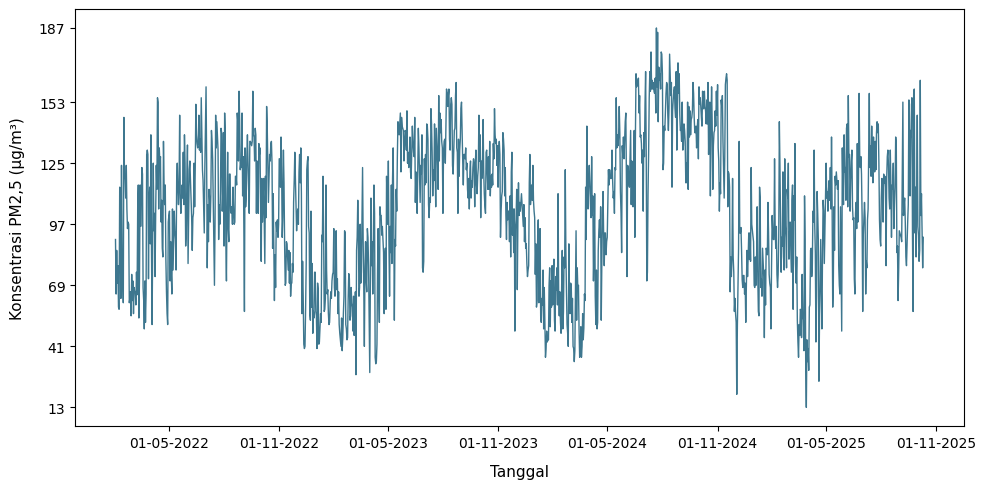

Periode data : 01-02-2022 - 10-10-2025
Total        : 1348 hari
Rentang PM2.5: 13 - 187 µg/m³


In [9]:
df_sorted = df_processed.sort_values('Tanggal').reset_index(drop=True)

plt.figure(figsize=(10, 5))
plt.plot(df_sorted['Tanggal'], df_sorted['Konsentrasi PM2.5'],
         linewidth=1, alpha=0.8, color="#0D5573")

min_value = df_sorted['Konsentrasi PM2.5'].min()
max_value = df_sorted['Konsentrasi PM2.5'].max()
padding   = (max_value - min_value) * 0.05
plt.ylim(min_value - padding, max_value + padding)
plt.yticks([13, 41, 69, 97, 125, 153, 187])

import matplotlib.dates as mdates
ax = plt.gca()
ax.xaxis.set_major_formatter(mdates.DateFormatter('%d-%m-%Y'))
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=6))
plt.xticks(ha='center')
ax.tick_params(axis='x', bottom=True, top=False, labelbottom=True)
ax.tick_params(axis='y', left=True, right=False)
plt.xlabel('Tanggal', fontsize=11, labelpad=10)
plt.ylabel('Konsentrasi PM2,5 (\u00b5g/m\u00b3)', fontsize=11, labelpad=10)
plt.tight_layout()
plt.savefig(f'{OUTPUT_ANALISIS}/visualizations/time_series_grafik.png',
            dpi=300, bbox_inches='tight')
plt.show()

print(f"Periode data : {df_sorted['Tanggal'].min().strftime('%d-%m-%Y')} "
      f"- {df_sorted['Tanggal'].max().strftime('%d-%m-%Y')}")
print(f"Total        : {len(df_sorted)} hari")
print(f"Rentang PM2.5: {min_value:.0f} - {max_value:.0f} \u00b5g/m\u00b3")

## 3.1.2  Analisis Autokorelasi (ACF)

> Analisis ACF terhadap `df_processed` untuk mengidentifikasi **pola musiman**.
> Garis merah putus-putus menandai lag **365** dan **730** hari (siklus tahunan).

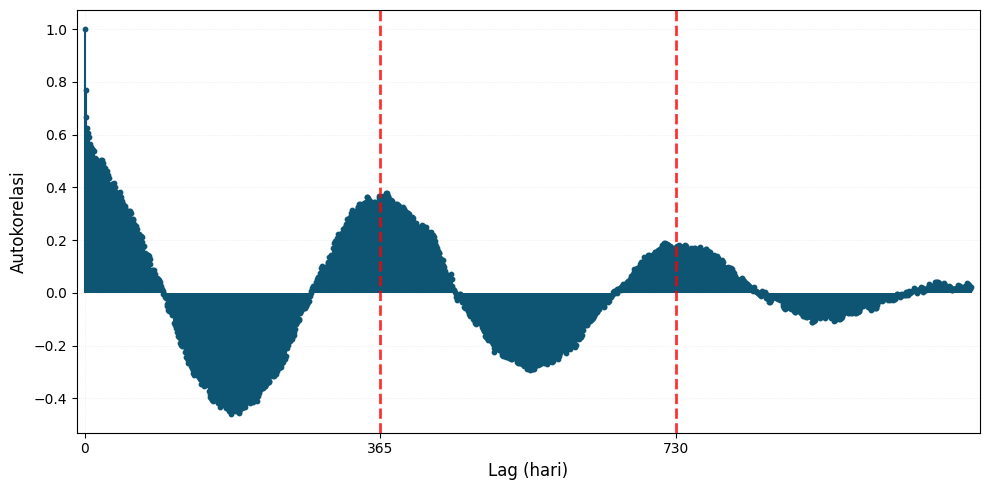

In [10]:
df_ACF     = df_processed[['Tanggal', 'Konsentrasi PM2.5']].copy().set_index('Tanggal')
data       = df_ACF['Konsentrasi PM2.5']
nlags      = min(1095, len(data) - 1)
acf_values = acf(data, nlags=nlags, fft=True)

fig, ax = plt.subplots(figsize=(10, 5))
lags = np.arange(len(acf_values))
ax.vlines(lags, 0, acf_values, colors='#0D5573', linewidth=1.5)
ax.scatter(lags, acf_values, color='#0D5573', s=10, zorder=3)

for sp in [365, 730]:
    if len(acf_values) > sp:
        ax.axvline(x=sp, color='red', linestyle='--', linewidth=2, alpha=0.8, zorder=10)

ax.set_xticks([0, 365, 730])
ax.set_xlabel('Lag (hari)', fontsize=12)
ax.set_ylabel('Autokorelasi', fontsize=12)
ax.grid(True, alpha=0.3, linestyle=':', linewidth=0.5)
ax.set_xlim(-10, len(acf_values) + 10)
plt.tight_layout()
plt.savefig(f'{OUTPUT_ANALISIS}/visualizations/acf_pm25.png',
            dpi=300, bbox_inches='tight')
plt.show()

---
# 3.2 Pemodelan
---

## 3.2.1 Fungsi Utilitas: Dataset & Model LSTM

In [11]:
def create_dataset(data, window_size):
    """Membuat sekuens windowed untuk input LSTM."""
    X, y = [], []
    for i in range(window_size, len(data)):
        X.append(data[i - window_size:i])
        y.append(data[i])
    return np.array(X), np.array(y)


def build_lstm_model(window_size, units1, units2, dropout_rate, learning_rate):
    """Membangun arsitektur 2-layer LSTM."""
    model = Sequential([
        LSTM(units1, return_sequences=True, input_shape=(window_size, 1)),
        LSTM(units2, return_sequences=False),
        Dropout(dropout_rate),
        Dense(1)
    ])
    model.compile(optimizer=Adam(learning_rate=learning_rate), loss='mse')
    return model

print("Utility functions defined")

Utility functions defined


## 3.2.2 Fungsi Walk-Forward Validation

In [12]:
def walk_forward_validation(df_processed, window_size, step,
                            units1, units2, dropout_rate, batch_size, learning_rate,
                            epochs, model_name="Model", output_dir="results", verbose=True):

    # ══════════════════════════════════════════════════════════════════════════
    # KONFIGURASI UKURAN DATA
    # ══════════════════════════════════════════════════════════════════════════
    SEASONAL_PERIOD   = 365
    TRAIN_SIZE        = 2 * SEASONAL_PERIOD   # 730 hari (2 tahun)
    VAL_SIZE          = SEASONAL_PERIOD       # 365 hari (1 tahun)
    TEST_SIZE         = step                  # 30 hari per fold
    MIN_DATA_REQUIRED = TRAIN_SIZE + VAL_SIZE + TEST_SIZE  # minimal 1125 hari

    data_original = df_processed['Konsentrasi PM2.5'].values
    dates         = pd.to_datetime(df_processed['Tanggal']).values

    if len(data_original) < MIN_DATA_REQUIRED:
        raise ValueError(
            f"Data tidak cukup!\n"
            f"  Required : {MIN_DATA_REQUIRED} days\n"
            f"  Available: {len(data_original)} days"
        )

    # starting_position = titik awal test pertama (setelah train+val awal)
    starting_position     = TRAIN_SIZE + VAL_SIZE   # index 1095
    results               = []
    fold_splits           = []
    all_train_predictions = []
    all_val_predictions   = []
    all_test_predictions  = []
    fold1_history_phase1  = None   

    if verbose:
        print(f"\n{'='*110}")
        print(f"WALK-FORWARD VALIDATION (EXPANDING WINDOW): {model_name}")
        print(f"{'='*110}")
        print(f"Total data: {len(data_original)} days | Window: {window_size} | Step: {step}")
        print(f"{'='*110}\n")
        print(f"{'Fold':<6} {'Train':<8} {'Val':<8} {'Test':<8} "
              f"{'Train RMSE':<12} {'Val RMSE':<12} {'Test RMSE':<12} "
              f"{'Epoch P1':<10} {'Epoch P2':<10} {'Duration(s)'}")
        print("\u2500"*110)

    fold_num = 1

    # ══════════════════════════════════════════════════════════════════════════
    # LOOP WALK-FORWARD (EXPANDING WINDOW)
    # setiap iterasi menggeser test window sebesar `step` hari ke depan
    # ukuran train terus bertambah (expanding), val & test tetap
    # ══════════════════════════════════════════════════════════════════════════
    for i in range(starting_position, len(data_original) - TEST_SIZE, step):
        try:
            fold_start = time.time()

            # ── PEMBAGIAN DATA PER FOLD ────────────────────────────────────
            train_val_end = i
            val_start     = train_val_end - VAL_SIZE   # val selalu 365 hari terakhir sebelum test
            train_end     = val_start                  # train: dari awal sampai sebelum val
            test_start    = train_val_end
            test_end      = test_start + TEST_SIZE

            if train_end < TRAIN_SIZE or test_end > len(data_original):
                fold_num += 1
                continue

            train_data  = data_original[0:train_end]
            val_data    = data_original[val_start:train_val_end]
            test_data   = data_original[test_start:test_end]
            train_dates = dates[0:train_end]
            val_dates   = dates[val_start:train_val_end]
            test_dates  = dates[test_start:test_end]

            if len(val_data) != VAL_SIZE or len(test_data) != TEST_SIZE:
                fold_num += 1
                continue

            # Simpan info pembagian fold untuk dokumentasi
            fold_splits.append({
                'fold': fold_num,
                'train_start': train_dates[0],  'train_end': train_dates[-1],
                'train_count': len(train_data),
                'val_start':   val_dates[0],    'val_end':   val_dates[-1],
                'val_count':   len(val_data),
                'test_start':  test_dates[0],   'test_end':  test_dates[-1],
                'test_count':  len(test_data)
            })

            # ══════════════════════════════════════════════════════════════
            # PHASE 1: TRAIN → VALIDASI
            # Tujuan: menemukan epoch optimal via early stopping
            # ══════════════════════════════════════════════════════════════

            # ── NORMALISASI (Z-Score) ──────────────────────────────────────
            # Fit scaler HANYA pada data train → cegah data leakage
            # val & test dinormalisasi menggunakan mean/std dari train
            train_mean   = np.mean(train_data)
            train_std    = np.std(train_data, ddof=1)
            train_scaled = (train_data - train_mean) / train_std
            val_scaled   = (val_data   - train_mean) / train_std

            # ── SLIDING WINDOW (Windowing) ─────────────────────────────────
            # Membentuk sekuens input X (window_size hari) → target y (hari berikutnya)
            X_train, y_train       = create_dataset(train_scaled, window_size)

            # Untuk val: gabungkan train+val agar window tidak putus di batas
            # lalu ambil hanya bagian val-nya (len(val_data) baris terakhir)
            combined_for_val       = np.concatenate([train_scaled, val_scaled])
            X_val_temp, y_val_temp = create_dataset(combined_for_val, window_size)
            X_val = X_val_temp[-len(val_data):]
            y_val = y_val_temp[-len(val_data):]

            if len(X_train) == 0 or len(X_val) == 0:
                fold_num += 1
                continue

            # Reshape ke format LSTM: (samples, timesteps, features)
            X_train = X_train.reshape(-1, window_size, 1)
            X_val   = X_val.reshape(-1, window_size, 1)

            # ── PELATIHAN MODEL PHASE 1 ────────────────────────────────────
            # Early stopping monitor val_loss → simpan bobot terbaik
            # ReduceLROnPlateau → turunkan lr jika val_loss stagnan
            model_phase1   = build_lstm_model(window_size, units1, units2, dropout_rate, learning_rate)
            history_phase1 = model_phase1.fit(
                X_train, y_train,
                validation_data=(X_val, y_val),
                epochs=epochs, batch_size=batch_size, verbose=0,
                callbacks=[
                    EarlyStopping(monitor='val_loss', patience=10,
                                  restore_best_weights=True, verbose=0),
                    ReduceLROnPlateau(monitor='val_loss', factor=0.5,
                                     patience=5, min_lr=1e-6, verbose=0)
                ]
            )

            # Simpan history fold 1 untuk visualisasi kurva val-loss
            if fold_num == 1:
                fold1_history_phase1 = history_phase1

            # Epoch optimal = epoch dengan val_loss terkecil (digunakan Phase 2)
            optimal_epochs = np.argmin(history_phase1.history['val_loss']) + 1

            # ── PREDIKSI & INVERS NORMALISASI ─────────────────────────────
            # Prediksi dalam skala normal → kembalikan ke skala asli
            # Invers: x_asli = (x_scaled × std) + mean
            y_train_pred = (model_phase1.predict(X_train, verbose=0).flatten() * train_std) + train_mean
            y_val_pred   = (model_phase1.predict(X_val,   verbose=0).flatten() * train_std) + train_mean

            # Invers normalisasi untuk nilai aktual (y masih dalam skala normal)
            y_train_actual = (y_train * train_std) + train_mean
            y_val_actual   = (y_val   * train_std) + train_mean

            # ── PERHITUNGAN METRIK: RMSE ───────────────────────────────────
            train_rmse = np.sqrt(mean_squared_error(y_train_actual, y_train_pred))
            val_rmse   = np.sqrt(mean_squared_error(y_val_actual,   y_val_pred))

            # Simpan prediksi train per hari
            for date, actual, pred in zip(train_dates[window_size:],
                                          y_train_actual, y_train_pred):
                all_train_predictions.append({'fold': fold_num, 'date': date,
                    'actual': actual, 'predicted': pred, 'error': actual - pred,
                    'abs_error': abs(actual - pred), 'squared_error': (actual - pred)**2,
                    'model': model_name})

            # Simpan prediksi val per hari
            for date, actual, pred in zip(val_dates, y_val_actual, y_val_pred):
                all_val_predictions.append({'fold': fold_num, 'date': date,
                    'actual': actual, 'predicted': pred, 'error': actual - pred,
                    'abs_error': abs(actual - pred), 'squared_error': (actual - pred)**2,
                    'model': model_name})

            # ══════════════════════════════════════════════════════════════
            # PHASE 2: RETRAIN (TRAIN+VAL) → TEST
            # Tujuan: latih ulang dengan seluruh data yang tersedia (train+val)
            # menggunakan epoch optimal dari Phase 1 → prediksi test
            # ══════════════════════════════════════════════════════════════

            # ── NORMALISASI ULANG (Train+Val) ──────────────────────────────
            # Fit scaler baru dari gabungan train+val (data lebih banyak)
            combined_data   = np.concatenate([train_data, val_data])
            combined_mean   = np.mean(combined_data)
            combined_std    = np.std(combined_data, ddof=1)
            combined_scaled = (combined_data - combined_mean) / combined_std

            # ── SLIDING WINDOW (Train+Val) ─────────────────────────────────
            X_combined, y_combined = create_dataset(combined_scaled, window_size)
            X_combined = X_combined.reshape(-1, window_size, 1)

            # ── PELATIHAN MODEL PHASE 2 ────────────────────────────────────
            model_phase2   = build_lstm_model(window_size, units1, units2, dropout_rate, learning_rate)
            history_phase2 = model_phase2.fit(
                X_combined, y_combined,
                epochs=optimal_epochs, batch_size=batch_size, verbose=0
            )

            # ── MULTI-STEP ITERATIVE FORECASTING ──────────────────────────
            # Prediksi test dilakukan satu langkah sekaligus (iteratif)
            # hasil prediksi t dimasukkan kembali sebagai input untuk t+1
            # sehingga window selalu bergeser maju (rolling)
            current_sequence        = combined_scaled[-window_size:].copy()
            test_predictions_scaled = []

            for t in range(len(test_data)):
                # Bentuk input: (1, window_size, 1)
                X_input       = current_sequence.reshape(1, window_size, 1)
                # Prediksi satu langkah ke depan (skala normal)
                y_pred_scaled = model_phase2.predict(X_input, verbose=0).flatten()[0]
                test_predictions_scaled.append(y_pred_scaled)
                # Geser window: buang nilai terlama, tambah prediksi baru
                current_sequence = np.append(current_sequence[1:], y_pred_scaled)

            # ── INVERS NORMALISASI HASIL TEST ─────────────────────────────
            # Kembalikan prediksi test ke skala asli 
            y_test_pred = (np.array(test_predictions_scaled) * combined_std) + combined_mean

            # ── PERHITUNGAN METRIK: RMSE TEST ─────────────────────────────
            test_rmse = np.sqrt(mean_squared_error(test_data, y_test_pred))

            # Simpan prediksi test per hari
            for date, actual, pred in zip(test_dates, test_data, y_test_pred):
                all_test_predictions.append({'fold': fold_num, 'date': date,
                    'actual': actual, 'predicted': pred, 'error': actual - pred,
                    'abs_error': abs(actual - pred), 'squared_error': (actual - pred)**2,
                    'model': model_name})

            duration = time.time() - fold_start

            # Simpan ringkasan hasil fold
            results.append({
                'fold': fold_num, 'units1': units1, 'units2': units2,
                'dropout_rate': dropout_rate, 'batch_size': batch_size,
                'learning_rate': learning_rate, 'window_size': window_size,
                'train_size': len(train_data), 'val_size': len(val_data),
                'test_size': len(test_data),
                'train_rmse': train_rmse, 'val_rmse': val_rmse, 'test_rmse': test_rmse,
                'epochs_phase1': optimal_epochs,
                'epochs_phase2': len(history_phase2.history['loss']),
                'final_val_loss_phase1': min(history_phase1.history['val_loss']),
                'final_loss_phase2': history_phase2.history['loss'][-1],
                'duration_seconds': duration
            })

            if verbose:
                print(f"{fold_num:<6} {len(train_data):<8} {len(val_data):<8} {len(test_data):<8} "
                      f"{train_rmse:<12.4f} {val_rmse:<12.4f} {test_rmse:<12.4f} "
                      f"{optimal_epochs:<10} {len(history_phase2.history['loss']):<10} {duration:.2f}")

        except Exception as e:
            if verbose:
                print(f"Fold {fold_num}: Failed ({str(e)})")
            fold_num += 1
            continue

        fold_num += 1

    # ══════════════════════════════════════════════════════════════════════════
    # SIMPAN OUTPUT KE CSV
    # ══════════════════════════════════════════════════════════════════════════
    base_path = f"{OUTPUT_ANALISIS}/{output_dir}"
    for sub in ['summary', 'walkforward', 'visualizations']:
        os.makedirs(f"{base_path}/{sub}", exist_ok=True)

    if results:
        # Ringkasan pembagian fold (tanggal train/val/test tiap fold)
        pd.DataFrame(fold_splits).to_csv(
            f"{base_path}/summary/fold_splits.csv",
            index=False, sep=';', float_format='%.6f', decimal=',')
        # Ringkasan metrik semua fold
        pd.DataFrame(results).to_csv(
            f"{base_path}/summary/results_summary.csv",
            index=False, sep=';', float_format='%.6f', decimal=',')
        # Prediksi per hari untuk train, val, test
        for name, store in [('train', all_train_predictions),
                             ('val',   all_val_predictions),
                             ('test',  all_test_predictions)]:
            if store:
                pd.DataFrame(store).to_csv(
                    f"{base_path}/summary/{name}_predictions_all_folds.csv",
                    index=False, sep=';', float_format='%.6f', decimal=',')

    # ══════════════════════════════════════════════════════════════════════════
    # VISUALISASI KURVA VAL-LOSS FOLD 1 (Early Stopping)
    # Menunjukkan kapan model berhenti & epoch terbaik ditemukan
    # ══════════════════════════════════════════════════════════════════════════
    if fold1_history_phase1 is not None:
        val_loss      = fold1_history_phase1.history['val_loss']
        best_epoch    = np.argmin(val_loss) + 1
        best_val_loss = min(val_loss)
        stopped_epoch = len(val_loss)

        fig, ax = plt.subplots(figsize=(10, 5))
        ax.plot(range(1, stopped_epoch + 1), val_loss,
                color='tomato', linewidth=2, label='Val Loss')
        ax.scatter([best_epoch], [best_val_loss], color='green', zorder=5, s=100,
                   label=f'Best Epoch ({best_epoch})')
        ax.axvline(x=best_epoch, color='green', linestyle='--', alpha=0.6)
        if stopped_epoch > best_epoch:
            ax.axvline(x=stopped_epoch, color='gray', linestyle=':', alpha=0.8,
                       label=f'Early Stopping (Epoch {stopped_epoch})')
        ax.set_xlabel('Epoch')
        ax.set_ylabel('Val Loss (MSE)')
        ax.legend()
        ax.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.savefig(f"{base_path}/visualizations/fold1_phase1_val_loss.png",
                    dpi=150, bbox_inches='tight')
        plt.show()

    if verbose:
        results_df = pd.DataFrame(results)
        print(f"\n{'='*80}")
        print(f"SUMMARY: {model_name}")
        print(f"{'='*80}")
        print(f"Jumlah fold  : {len(results)}")
        print(f"Train RMSE   : {results_df['train_rmse'].mean():.4f} \u00b1 {results_df['train_rmse'].std():.4f}")
        print(f"Val RMSE     : {results_df['val_rmse'].mean():.4f} \u00b1 {results_df['val_rmse'].std():.4f}")
        print(f"Test RMSE    : {results_df['test_rmse'].mean():.4f} \u00b1 {results_df['test_rmse'].std():.4f}")
        print(f"Total durasi : {results_df['duration_seconds'].sum():.2f}s")
        print(f"{'='*80}")

    return results

print("walk_forward_validation defined")

walk_forward_validation defined


## 3.2.3 Evaluasi Model Baseline LSTM


BASELINE EVALUATION

Baseline Configuration:
  window_size         : 365
  step                : 30
  units1              : 64
  units2              : 64
  dropout_rate        : 0.0
  batch_size          : 32
  learning_rate       : 0.001
  epochs              : 100

WALK-FORWARD VALIDATION (EXPANDING WINDOW): Baseline
Total data: 1348 days | Window: 365 | Step: 30

Fold   Train    Val      Test     Train RMSE   Val RMSE     Test RMSE    Epoch P1   Epoch P2   Duration(s)
──────────────────────────────────────────────────────────────────────────────────────────────────────────────


I0000 00:00:1794276416.062909      23 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1794276416.069074      23 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5
I0000 00:00:1794276420.352944      69 cuda_dnn.cc:529] Loaded cuDNN version 91002


1      730      365      30       16.8069      19.3595      28.6588      31         31         47.83
2      760      365      30       16.7436      20.7060      40.5038      34         34         47.94
3      790      365      30       17.1560      19.8934      24.3593      40         40         56.04
4      820      365      30       18.0504      20.2470      27.7384      21         21         36.39
5      850      365      30       17.4607      20.5813      43.0523      17         17         32.65
6      880      365      30       17.6650      20.5375      24.4534      15         15         31.55
7      910      365      30       17.8691      20.0811      16.1937      19         19         36.99
8      940      365      30       17.7148      20.0940      33.0119      23         23         42.73


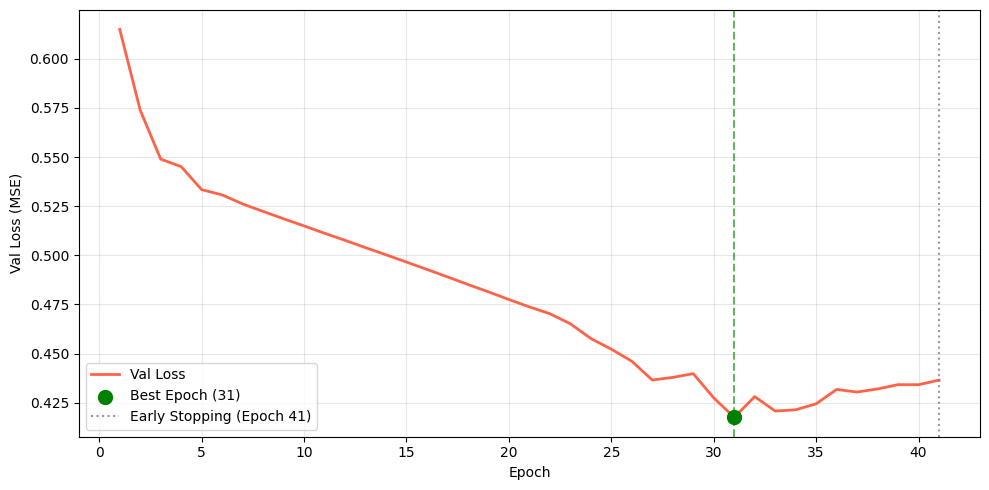


SUMMARY: Baseline
Jumlah fold  : 8
Train RMSE   : 17.4333 ± 0.4854
Val RMSE     : 20.1875 ± 0.4379
Test RMSE    : 29.7464 ± 8.8589
Total durasi : 332.14s

BASELINE SUMMARY
Val RMSE:  20.1875 ± 0.4379
Test RMSE: 29.7464 ± 8.8589
Duration:  332.14s total


,fold,train_start,train_end,train_count,val_start,val_end,val_count,test_start,test_end,test_count
0,1,2022-02-01,2024-01-31,730,2024-02-01,2025-01-30,365,2025-01-31,2025-03-01,30
1,2,2022-02-01,2024-03-01,760,2024-03-02,2025-03-01,365,2025-03-02,2025-03-31,30
2,3,2022-02-01,2024-03-31,790,2024-04-01,2025-03-31,365,2025-04-01,2025-04-30,30
3,4,2022-02-01,2024-04-30,820,2024-05-01,2025-04-30,365,2025-05-01,2025-05-30,30
4,5,2022-02-01,2024-05-30,850,2024-05-31,2025-05-30,365,2025-05-31,2025-06-29,30
5,6,2022-02-01,2024-06-29,880,2024-06-30,2025-06-29,365,2025-06-30,2025-07-29,30
6,7,2022-02-01,2024-07-29,910,2024-07-30,2025-07-29,365,2025-07-30,2025-08-28,30
7,8,2022-02-01,2024-08-28,940,2024-08-29,2025-08-28,365,2025-08-29,2025-09-27,30


In [13]:
BASELINE_CONFIG = {
    'window_size'  : 365,
    'step'         : 30,
    'units1'       : 64,
    'units2'       : 64,
    'dropout_rate' : 0.0,
    'batch_size'   : 32,
    'learning_rate': 0.001,
    'epochs'       : 100
}

print("\n" + "="*80)
print("BASELINE EVALUATION")
print("="*80)
print("\nBaseline Configuration:")
for k, v in BASELINE_CONFIG.items():
    print(f"  {k:<20}: {v}")

results_baseline    = walk_forward_validation(
    df_processed, **BASELINE_CONFIG,
    model_name="Baseline", output_dir="baseline", verbose=True
)
results_baseline_df = pd.DataFrame(results_baseline)

print(f"\n{'='*80}")
print("BASELINE SUMMARY")
print(f"{'='*80}")
print(f"Val RMSE:  {results_baseline_df['val_rmse'].mean():.4f} \u00b1 {results_baseline_df['val_rmse'].std():.4f}")
print(f"Test RMSE: {results_baseline_df['test_rmse'].mean():.4f} \u00b1 {results_baseline_df['test_rmse'].std():.4f}")
print(f"Duration:  {results_baseline_df['duration_seconds'].sum():.2f}s total")
print(f"{'='*80}")

df_baseline_splits = pd.read_csv(
    f"{OUTPUT_ANALISIS}/baseline/summary/fold_splits.csv", sep=';')
display(df_baseline_splits)

## 3.2.4 Definisi Fungsi Objektif Bayesian Optimization

In [14]:
bo_iteration_details = []
bo_iteration_number  = 0

def bayesian_objective(**kwargs):
    global bo_iteration_number, bo_iteration_details
    bo_iteration_number += 1

    units1        = int(kwargs.get('units1', 50))
    units2        = int(kwargs.get('units2', 50))
    dropout_rate  = kwargs.get('dropout_rate', 0.1)
    batch_size    = int(round(kwargs.get('batch_size', 16)))
    learning_rate = kwargs.get('learning_rate', 0.001)

    window_size       = 365
    step              = 30
    SEASONAL_PERIOD   = 365
    TRAIN_SIZE        = 2 * SEASONAL_PERIOD
    VAL_SIZE          = SEASONAL_PERIOD
    starting_position = TRAIN_SIZE + VAL_SIZE
    max_folds         = 8

    fold_details    = []
    val_rmse_scores = []
    iter_start      = time.time()
    data_original   = df_processed['Konsentrasi PM2.5'].values
    TEST_SIZE       = step

    fold = 0
    for i in range(starting_position, len(data_original) - TEST_SIZE, step):
        if fold >= max_folds:
            break
        try:
            train_val_end = i
            val_start     = train_val_end - VAL_SIZE
            train_end     = val_start

            if train_end < TRAIN_SIZE:
                continue

            train_data = data_original[0:train_end]
            val_data   = data_original[val_start:train_val_end]

            if len(val_data) != VAL_SIZE:
                continue

            train_mean   = np.mean(train_data)
            train_std    = np.std(train_data, ddof=1)
            train_scaled = (train_data - train_mean) / train_std
            val_scaled   = (val_data   - train_mean) / train_std

            X_train, y_train       = create_dataset(train_scaled, window_size)
            combined_for_val       = np.concatenate([train_scaled, val_scaled])
            X_val_temp, y_val_temp = create_dataset(combined_for_val, window_size)
            X_val = X_val_temp[-len(val_data):]
            y_val = y_val_temp[-len(val_data):]

            if len(X_train) == 0 or len(X_val) == 0:
                continue

            X_train = X_train.reshape(-1, window_size, 1)
            X_val   = X_val.reshape(-1, window_size, 1)

            model   = build_lstm_model(window_size, units1, units2, dropout_rate, learning_rate)
            history = model.fit(
                X_train, y_train,
                validation_data=(X_val, y_val),
                epochs=100, batch_size=batch_size, verbose=0,
                callbacks=[EarlyStopping(monitor='val_loss', patience=10,
                                         restore_best_weights=True, verbose=0)]
            )

            optimal_epoch = np.argmin(history.history['val_loss']) + 1
            y_val_pred    = (model.predict(X_val, verbose=0).flatten() * train_std) + train_mean
            y_val_actual  = (y_val * train_std) + train_mean
            val_rmse      = np.sqrt(mean_squared_error(y_val_actual, y_val_pred))
            val_rmse_scores.append(val_rmse)

            fold_details.append({
                'iteration': bo_iteration_number, 'fold': fold + 1,
                'train_size': len(train_data),    'val_size': len(val_data),
                'units1': units1,   'units2': units2,
                'dropout_rate': dropout_rate,     'batch_size': batch_size,
                'learning_rate': learning_rate,   'val_rmse': val_rmse,
                'train_loss': history.history['loss'][-1],
                'val_loss':   history.history['val_loss'][-1],
                'optimal_epoch': optimal_epoch
            })
            fold += 1

        except Exception:
            continue

    if not val_rmse_scores:
        return -999999

    avg_val_rmse = np.mean(val_rmse_scores)
    bo_iteration_details.append({
        'iteration': bo_iteration_number,
        'units1': units1,   'units2': units2,
        'dropout_rate': dropout_rate,   'batch_size': batch_size,
        'learning_rate': learning_rate, 'avg_val_rmse': avg_val_rmse,
        'num_folds': len(fold_details),
        'duration_seconds': time.time() - iter_start
    })

    os.makedirs(f"{OUTPUT_ANALISIS}/bo_iterations/detailed", exist_ok=True)
    pd.DataFrame(fold_details).to_csv(
        f"{OUTPUT_ANALISIS}/bo_iterations/detailed/iteration_{bo_iteration_number:02d}_folds.csv",
        index=False, sep=';', float_format='%.6f', decimal=',')

    print(f"  Iter {bo_iteration_number:2d} | Val RMSE: {avg_val_rmse:.4f} | Folds: {len(fold_details)}")
    return -avg_val_rmse

print("bayesian_objective defined")

bayesian_objective defined


## 3.2.5 Jalankan Bayesian Optimization

In [15]:
print(f"\n{'='*80}")
print("STARTING BAYESIAN OPTIMIZATION")
print(f"{'='*80}\n")

pbounds = {
    'units1'       : (32, 256),
    'units2'       : (32, 256),
    'dropout_rate' : (0.1, 0.5),
    'batch_size'   : (16, 128),
    'learning_rate': (0.0001, 0.001)
}

print("Search Space:")
for param, bounds in pbounds.items():
    print(f"  {param:<20}: {bounds}")

bo_iteration_details = []
bo_iteration_number  = 0

optimizer = BayesianOptimization(
    f=bayesian_objective,
    pbounds=pbounds,
    random_state=SEED,
    verbose=2
)

optimizer.maximize(
    init_points=10,   # Eksplorasi acak
    n_iter=20         # Iterasi Bayesian
)

pd.DataFrame(bo_iteration_details).to_csv(
    f"{OUTPUT_ANALISIS}/bo_iterations/detailed/iterations_summary.csv",
    index=False, sep=';', float_format='%.6f', decimal=',')

best_params = optimizer.max['params']
best_score  = -optimizer.max['target']

print(f"\n{'='*80}")
print("BAYESIAN OPTIMIZATION COMPLETED")
print(f"{'='*80}")
print(f"\nBest Configuration:")
print(f"  units1:        {int(best_params['units1'])}")
print(f"  units2:        {int(best_params['units2'])}")
print(f"  dropout:       {best_params['dropout_rate']:.4f}")
print(f"  batch_size:    {int(round(best_params['batch_size']))}")
print(f"  learning_rate: {best_params['learning_rate']:.6f}")
print(f"\nBest Val RMSE: {best_score:.4f}")
print(f"{'='*80}")


STARTING BAYESIAN OPTIMIZATION

Search Space:
  units1              : (32, 256)
  units2              : (32, 256)
  dropout_rate        : (0.1, 0.5)
  batch_size          : (16, 128)
  learning_rate       : (0.0001, 0.001)
|   iter    |  target   |  units1   |  units2   | dropou... | batch_... | learni... |
-------------------------------------------------------------------------------------
  Iter  1 | Val RMSE: 20.9180 | Folds: 8
| 1         | -20.91804 | 115.89698 | 244.96000 | 0.3927975 | 83.049750 | 0.0002404 |
  Iter  2 | Val RMSE: 20.8031 | Folds: 8
| 2         | -20.80311 | 66.942772 | 45.010729 | 0.4464704 | 83.324881 | 0.0007372 |
  Iter  3 | Val RMSE: 20.9554 | Folds: 8
| 3         | -20.95537 | 36.610926 | 249.25980 | 0.4329770 | 39.781980 | 0.0002636 |
  Iter  4 | Val RMSE: 21.2271 | Folds: 8
| 4         | -21.22711 | 73.082610 | 100.15026 | 0.3099025 | 64.377842 | 0.0003621 |
  Iter  5 | Val RMSE: 20.4925 | Folds: 8
| 5         | -20.49248 | 169.05504 | 63.246624 | 0.216

## 3.2.6 Evaluasi Model BO-LSTM


BO-LSTM EVALUATION

WALK-FORWARD VALIDATION (EXPANDING WINDOW): BO_LSTM
Total data: 1348 days | Window: 365 | Step: 30

Fold   Train    Val      Test     Train RMSE   Val RMSE     Test RMSE    Epoch P1   Epoch P2   Duration(s)
──────────────────────────────────────────────────────────────────────────────────────────────────────────────
1      730      365      30       17.2776      19.7107      26.5730      55         55         43.27
2      760      365      30       17.6317      20.5672      42.3486      50         50         43.05
3      790      365      30       17.2295      19.8054      22.4825      63         63         51.33
4      820      365      30       17.6852      20.0135      24.8868      54         54         45.93
5      850      365      30       17.6300      20.6696      25.2865      45         45         42.77
6      880      365      30       17.5733      20.3219      24.8868      59         59         52.52
7      910      365      30       17.7928      20.0482 

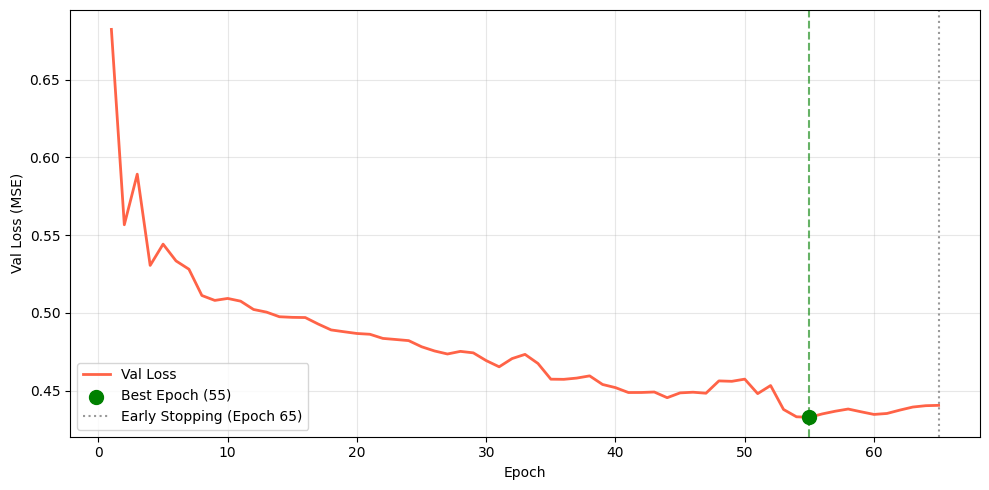


SUMMARY: BO_LSTM
Jumlah fold  : 8
Train RMSE   : 17.5710 ± 0.2082
Val RMSE     : 20.1782 ± 0.3438
Test RMSE    : 26.7632 ± 7.1853
Total durasi : 370.39s

BO-LSTM SUMMARY
Val RMSE:  20.1782 ± 0.3438
Test RMSE: 26.7632 ± 7.1853
Duration:  370.39s total


,fold,train_start,train_end,train_count,val_start,val_end,val_count,test_start,test_end,test_count
0,1,2022-02-01,2024-01-31,730,2024-02-01,2025-01-30,365,2025-01-31,2025-03-01,30
1,2,2022-02-01,2024-03-01,760,2024-03-02,2025-03-01,365,2025-03-02,2025-03-31,30
2,3,2022-02-01,2024-03-31,790,2024-04-01,2025-03-31,365,2025-04-01,2025-04-30,30
3,4,2022-02-01,2024-04-30,820,2024-05-01,2025-04-30,365,2025-05-01,2025-05-30,30
4,5,2022-02-01,2024-05-30,850,2024-05-31,2025-05-30,365,2025-05-31,2025-06-29,30
5,6,2022-02-01,2024-06-29,880,2024-06-30,2025-06-29,365,2025-06-30,2025-07-29,30
6,7,2022-02-01,2024-07-29,910,2024-07-30,2025-07-29,365,2025-07-30,2025-08-28,30
7,8,2022-02-01,2024-08-28,940,2024-08-29,2025-08-28,365,2025-08-29,2025-09-27,30


In [16]:
print("\n" + "="*80)
print("BO-LSTM EVALUATION")
print("="*80)

results_best = walk_forward_validation(
    df_processed,
    window_size=365, step=30,
    units1=int(best_params['units1']),
    units2=int(best_params['units2']),
    dropout_rate=best_params['dropout_rate'],
    batch_size=int(round(best_params['batch_size'])),
    learning_rate=best_params['learning_rate'],
    epochs=100,
    model_name="BO_LSTM",
    output_dir="bo_best",
    verbose=True
)

results_best_df = pd.DataFrame(results_best)

print(f"\n{'='*80}")
print("BO-LSTM SUMMARY")
print(f"{'='*80}")
print(f"Val RMSE:  {results_best_df['val_rmse'].mean():.4f} \u00b1 {results_best_df['val_rmse'].std():.4f}")
print(f"Test RMSE: {results_best_df['test_rmse'].mean():.4f} \u00b1 {results_best_df['test_rmse'].std():.4f}")
print(f"Duration:  {results_best_df['duration_seconds'].sum():.2f}s total")
print(f"{'='*80}")

df_bo_splits = pd.read_csv(
    f"{OUTPUT_ANALISIS}/bo_best/summary/fold_splits.csv", sep=';')
display(df_bo_splits)

-------------
# 3.3 Perbandingan Model
----------

## 3.3.1 Perbandingan RMSE Baseline vs BO-LSTM

In [17]:
comparison_final = pd.DataFrame([
    {
        'Model'          : 'Baseline',
        'Val RMSE'       : results_baseline_df['val_rmse'].mean(),
        'Val Std'        : results_baseline_df['val_rmse'].std(),
        'Test RMSE'      : results_baseline_df['test_rmse'].mean(),
        'Test Std'       : results_baseline_df['test_rmse'].std(),
        'Avg Duration(s)': results_baseline_df['duration_seconds'].mean()
    },
    {
        'Model'          : 'BO-LSTM',
        'Val RMSE'       : results_best_df['val_rmse'].mean(),
        'Val Std'        : results_best_df['val_rmse'].std(),
        'Test RMSE'      : results_best_df['test_rmse'].mean(),
        'Test Std'       : results_best_df['test_rmse'].std(),
        'Avg Duration(s)': results_best_df['duration_seconds'].mean()
    }
])

improvement = ((results_baseline_df['test_rmse'].mean() - results_best_df['test_rmse'].mean())
               / results_baseline_df['test_rmse'].mean() * 100)

print(f"\n{'='*80}")
print("FINAL COMPARISON: WALK-FORWARD")
print(f"{'='*80}")
print(comparison_final.to_string(index=False))
print(f"\nTest RMSE Improvement: {improvement:+.2f}%")
print(f"{'='*80}")

comparison_final.to_csv(
    f'{OUTPUT_ANALISIS}/statistics/final_comparison.csv',
    index=False, sep=';', float_format='%.6f', decimal=',')


FINAL COMPARISON: WALK-FORWARD
   Model  Val RMSE  Val Std  Test RMSE  Test Std  Avg Duration(s)
Baseline 20.187470 0.437866  29.746434  8.858897        41.517105
 BO-LSTM 20.178192 0.343791  26.763223  7.185311        46.298152

Test RMSE Improvement: +10.03%


## 3.3.2 Uji Statistik Diebold-Mariano (DM Test)

In [18]:
# ── Load data prediksi ────────────────────────────────────────────────────────
df_pred_baseline = pd.read_csv(
    f'{OUTPUT_ANALISIS}/baseline/summary/test_predictions_all_folds.csv',
    sep=';', decimal=',')
df_pred_bo = pd.read_csv(
    f'{OUTPUT_ANALISIS}/bo_best/summary/test_predictions_all_folds.csv',
    sep=';', decimal=',')

df_merged = pd.merge(
    df_pred_baseline[['date', 'fold', 'actual', 'predicted']],
    df_pred_bo[['date', 'fold', 'predicted']],
    on=['date', 'fold'], suffixes=('_baseline', '_bo')
).sort_values(['fold', 'date']).reset_index(drop=True)

actual        = df_merged['actual'].values
pred_baseline = df_merged['predicted_baseline'].values
pred_bo       = df_merged['predicted_bo'].values

# ── Step 1: Loss Differential ─────────────────────────────────────────────────
e1 = actual - pred_baseline
e2 = actual - pred_bo
d  = e1**2 - e2**2

# ── Step 2: Rata-rata Loss Differential ───────────────────────────────────────
n     = len(d)
d_bar = np.mean(d)

# ── Step 3: Long-Run Variance (Newey-West HAC) ────────────────────────────────
h         = 30
gamma_0   = np.var(d, ddof=0)
fold_ids  = df_merged['fold'].values
d_c       = d - d_bar
gamma_sum = 0.0

for k in range(1, h):
    same_fold       = fold_ids[k:] == fold_ids[:-k]
    gamma_k         = np.sum((d_c[k:] * d_c[:-k])[same_fold]) / n
    bartlett_weight = 1 - (k / h)
    gamma_sum      += bartlett_weight * gamma_k

long_run_var = gamma_0 + 2 * gamma_sum

# ── Step 4: Koreksi HLN & Standar Error ───────────────────────────────────────
F_HLN = (n + 1 - 2*h + h*(h-1)/n) / n
se_d  = np.sqrt(F_HLN * long_run_var)

# ── Step 5: Statistik Uji DM ──────────────────────────────────────────────────
dm_stat = d_bar / se_d

# ── Step 6: Keputusan (Uji Satu Sisi) ────────────────────────────────────────
p_value  = 1 - stats.t.cdf(dm_stat, df=n-1)
t_kritis = stats.t.ppf(0.95, df=n-1)

if p_value < 0.001:
    sig = "*** (p < 0.001) — Sangat signifikan"
elif p_value < 0.01:
    sig = "** (p < 0.01)  — Signifikan tinggi"
elif p_value < 0.05:
    sig = "* (p < 0.05)   — Signifikan"
else:
    sig = "ns (p \u2265 0.05)  — Tidak signifikan"

keputusan = 'TOLAK H\u2080' if (p_value < 0.05 and dm_stat > 0) else 'GAGAL TOLAK H\u2080'

# ── Ringkasan ─────────────────────────────────────────────────────────────────
print("\n" + "="*65)
print("           RINGKASAN HASIL DM TEST")
print("="*65)
rows = [
    ("n (total observasi)",         n),
    ("h (horizon prediksi)",        h),
    ("d\u0304",                    f"{d_bar:.6f}"),
    ("\u03b3\u02c60 (varians dasar)",  f"{gamma_0:.6f}"),
    ("2\u03c0f\u02c6d(0) (long-run var)", f"{long_run_var:.6f}"),
    ("F_HLN (faktor koreksi)",      f"{F_HLN:.6f}"),
    ("SE*(d\u0304)",               f"{se_d:.6f}"),
    ("DM*",                         f"{dm_stat:.6f}"),
    ("t_kritis (\u03b1=0.05, one-tailed)", f"{t_kritis:.4f}"),
    ("p-value (one-tailed)",        f"{p_value:.6f}"),
    ("Signifikansi",                sig),
    ("Keputusan",                   keputusan),
]
for label, val in rows:
    print(f"  {label:<38} {val}")
print("="*65)

# Simpan semua CSV
for fname, data_dict in [
    ('step1_loss_differential.csv', {
        'hari': range(1, n+1), 'fold': df_merged['fold'].values,
        'date': df_merged['date'].values, 'actual': actual,
        'pred_baseline': pred_baseline, 'pred_bo': pred_bo,
        'e1': e1, 'e2': e2, 'e1_sq': e1**2, 'e2_sq': e2**2, 'dt': d
    }),
    ('ringkasan_dm_test.csv', {
        'komponen': [r[0] for r in rows],
        'nilai':    [r[1] for r in rows]
    }),
]:
    pd.DataFrame(data_dict).to_csv(
        f'{OUTPUT_ANALISIS}/statistics/{fname}',
        index=False, sep=';', decimal=',', float_format='%.6f')


           RINGKASAN HASIL DM TEST
  n (total observasi)                    240
  h (horizon prediksi)                   30
  d̄                                     192.075156
  γˆ0 (varians dasar)                    402647.649981
  2πfˆd(0) (long-run var)                3327985.180671
  F_HLN (faktor koreksi)                 0.769271
  SE*(d̄)                                1600.038104
  DM*                                    0.120044
  t_kritis (α=0.05, one-tailed)          1.6513
  p-value (one-tailed)                   0.452275
  Signifikansi                           ns (p ≥ 0.05)  — Tidak signifikan
  Keputusan                              GAGAL TOLAK H₀


## 3.3.3 Visualisasi 

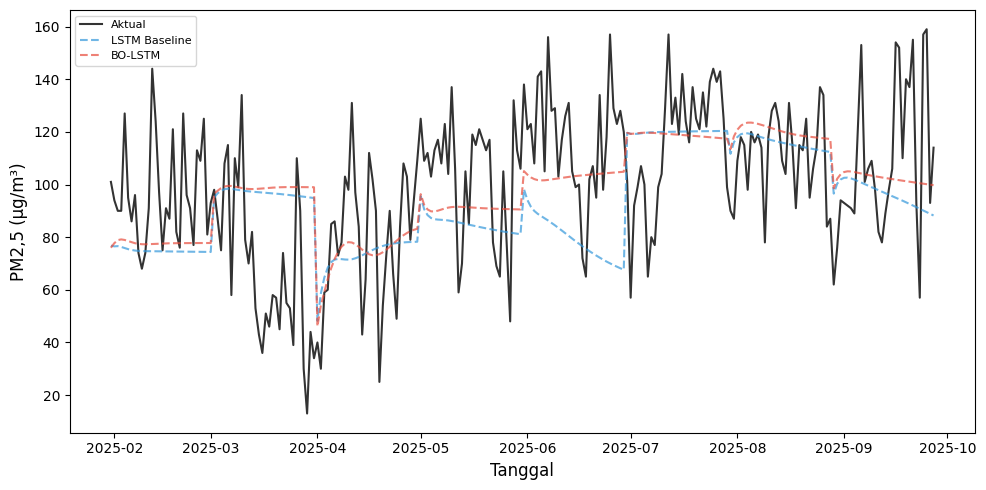

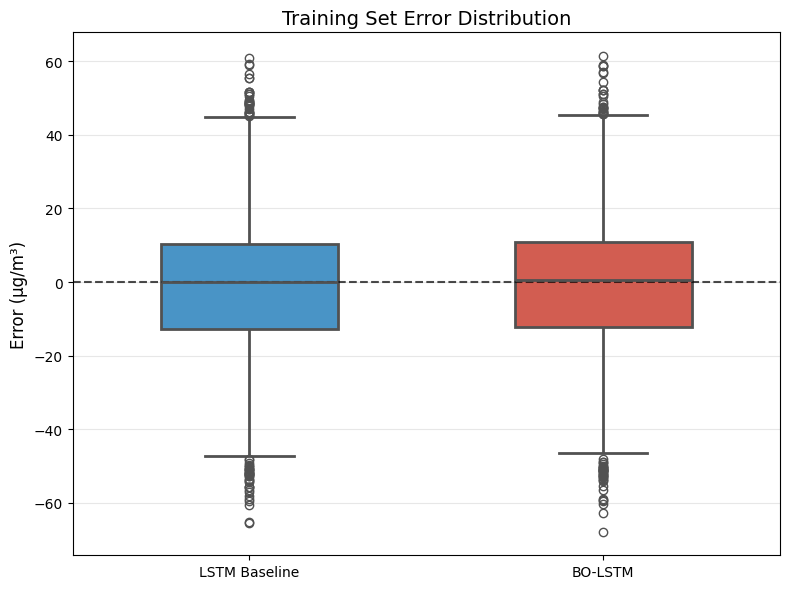

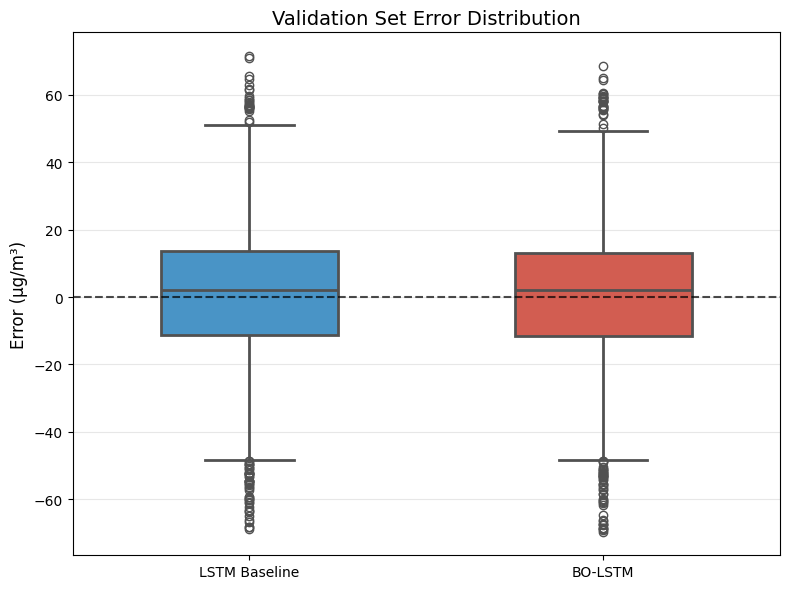

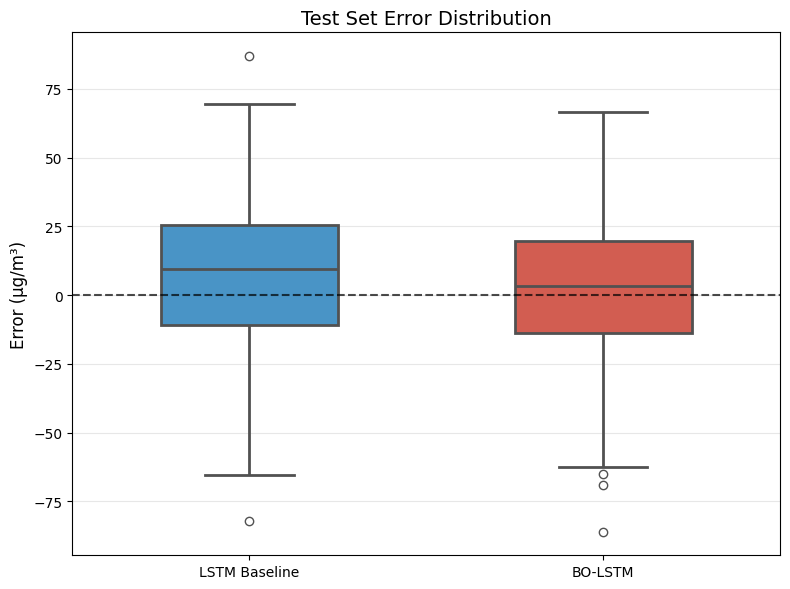


SUMMARY AKHIR
Evaluasi        Baseline RMSE   BO-LSTM RMSE    Improvement
----------------------------------------------------------------------
Training        17.4333         17.5710          -0.79%
Validation      20.1875         20.1782           0.05%
Testing         29.7464         26.7632          10.03%


In [19]:
# ── Load semua data prediksi ──────────────────────────────────────────────────
for split in ['train', 'val', 'test']:
    for model_tag, path in [('baseline', 'baseline'), ('bo', 'bo_best')]:
        key  = f'df_{split}_{model_tag}'
        temp = pd.read_csv(
            f'{OUTPUT_ANALISIS}/{path}/summary/{split}_predictions_all_folds.csv',
            sep=';', decimal=',')
        temp['date'] = pd.to_datetime(temp['date'])
        globals()[key] = temp


def calc_rmse(df):
    return np.mean([
        np.sqrt(np.mean((df[df['fold']==f]['actual'] -
                         df[df['fold']==f]['predicted'])**2))
        for f in df['fold'].unique()
    ])


# ── Plot 1: Time Series Test Set ──────────────────────────────────────────────
plt.figure(figsize=(10, 5))
plt.plot(df_test_baseline['date'], df_test_baseline['actual'],
         label='Aktual', color='black', linewidth=1.5, alpha=0.8)
plt.plot(df_test_baseline['date'], df_test_baseline['predicted'],
         label='LSTM Baseline', color='#3498db', linewidth=1.5, alpha=0.7, linestyle='--')
plt.plot(df_test_bo['date'], df_test_bo['predicted'],
         label='BO-LSTM', color='#e74c3c', linewidth=1.5, alpha=0.7, linestyle='--')
plt.xlabel('Tanggal', fontsize=12)
plt.ylabel('PM2,5 (\u00b5g/m\u00b3)', fontsize=12)
plt.legend(fontsize=8, loc='upper left')
plt.tight_layout()
plt.savefig(f'{OUTPUT_ANALISIS}/visualizations/timeseries_test.png',
            dpi=300, bbox_inches='tight')
plt.show()


# ── Plot 2-4: Boxplot Error per Split ────────────────────────────────────────
for split_name, df_b, df_o in [
    ('Training',   df_train_baseline, df_train_bo),
    ('Validation', df_val_baseline,   df_val_bo),
    ('Test',       df_test_baseline,  df_test_bo),
]:
    errs = pd.DataFrame({
        'Error': np.concatenate([df_b['actual'] - df_b['predicted'],
                                  df_o['actual'] - df_o['predicted']]),
        'Model': (['LSTM Baseline'] * len(df_b) + ['BO-LSTM'] * len(df_o))
    })
    plt.figure(figsize=(8, 6))
    sns.boxplot(data=errs, x='Model', y='Error',
                palette=['#3498db', '#e74c3c'], width=0.5, linewidth=2)
    plt.axhline(y=0, color='black', linestyle='--', linewidth=1.5, alpha=0.7)
    plt.xlabel('')
    plt.ylabel('Error (\u00b5g/m\u00b3)', fontsize=12)
    plt.title(f'{split_name} Set Error Distribution', fontsize=14)
    plt.grid(True, alpha=0.3, axis='y')
    plt.tight_layout()
    plt.savefig(
        f'{OUTPUT_ANALISIS}/visualizations/boxplot_{split_name.lower()}.png',
        dpi=300, bbox_inches='tight')
    plt.show()


# ── Summary Akhir ─────────────────────────────────────────────────────────────
print("\n" + "="*70)
print("SUMMARY AKHIR")
print("="*70)
print(f"{'Evaluasi':<15} {'Baseline RMSE':<15} {'BO-LSTM RMSE':<15} {'Improvement'}")
print("-"*70)
for label, df_b, df_o in [
    ('Training',   df_train_baseline, df_train_bo),
    ('Validation', df_val_baseline,   df_val_bo),
    ('Testing',    df_test_baseline,  df_test_bo),
]:
    rb = calc_rmse(df_b)
    ro = calc_rmse(df_o)
    print(f"{label:<15} {rb:<15.4f} {ro:<15.4f} {(1 - ro/rb)*100:>6.2f}%")
print("="*70)

---
*— End of Notebook —*